In [1]:

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

# Load the prepared dataset
df = pd.read_csv("data/credit_approval_dataset.csv")

# Separate features and target
X = df.drop(columns=["credit_risk"])
y = df["credit_risk"]

# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))


Training data: (29165, 17)
Testing data: (7292, 17)

Training target distribution:
credit_risk
0    0.88229
1    0.11771
Name: proportion, dtype: float64

Testing target distribution:
credit_risk
0    0.882337
1    0.117663
Name: proportion, dtype: float64


In [3]:

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])


In [4]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

# Compare results
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.8027,0.3247,0.6270,0.4278,0.7971
1,Decision Tree,0.7876,0.3088,0.6503,0.4188,0.7525
0,Logistic Regression,0.5779,0.1363,0.4848,0.2128,0.5502


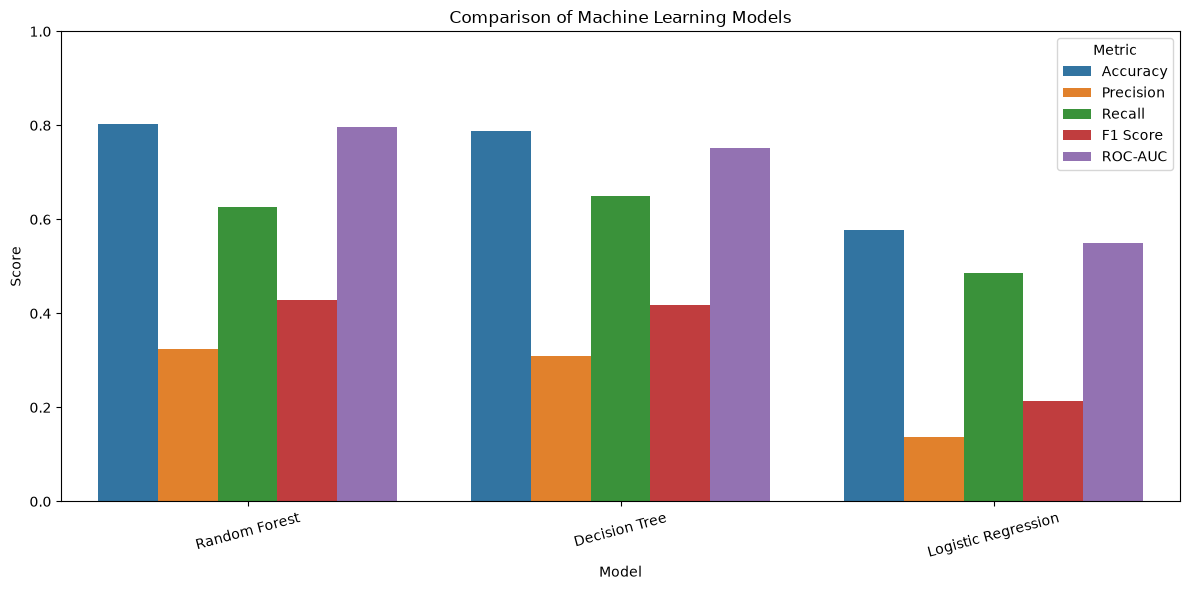

In [5]:

results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [6]:

# Select the best model using F1-score
best_model_name = results_df.iloc[0]["Model"]

print("Best model before tuning:", best_model_name)

# Define parameter options for each model
parameter_options = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100]
    },

    "Decision Tree": {
        "model__max_depth": [5, 10, 15, 20, None],
        "model__min_samples_leaf": [1, 2, 5, 10]
    },

    "Random Forest": {
        "model__n_estimators": [100, 150, 200],
        "model__max_depth": [10, 20, None],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": ["sqrt", 0.5]
    }
}

# Retrieve selected model
selected_model = trained_models[best_model_name]

# Parameter tuning
search = RandomizedSearchCV(
    estimator=selected_model,
    param_distributions=parameter_options[best_model_name],
    n_iter=6,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

# Best model
best_pipeline = search.best_estimator_

print("\nBest parameters:")
print(search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(search.best_score_, 4))


Best model before tuning: Random Forest
Fitting 3 folds for each of 6 candidates, totalling 18 fits



Best parameters:
{'model__n_estimators': 100, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': None}

Best cross-validation F1-score:
0.3874


In [7]:

# Make predictions
y_pred = best_pipeline.predict(X_test)

y_prob = best_pipeline.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("TUNED MODEL PERFORMANCE")
print("-----------------------")

print("Accuracy:", round(
    accuracy_score(y_test, y_pred), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))

print("F1 Score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


TUNED MODEL PERFORMANCE
-----------------------
Accuracy: 0.8013
Precision: 0.3236
Recall: 0.6317
F1 Score: 0.428
ROC-AUC: 0.7984

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.82      0.88      6434
           1       0.32      0.63      0.43       858

    accuracy                           0.80      7292
   macro avg       0.63      0.73      0.65      7292
weighted avg       0.87      0.80      0.83      7292



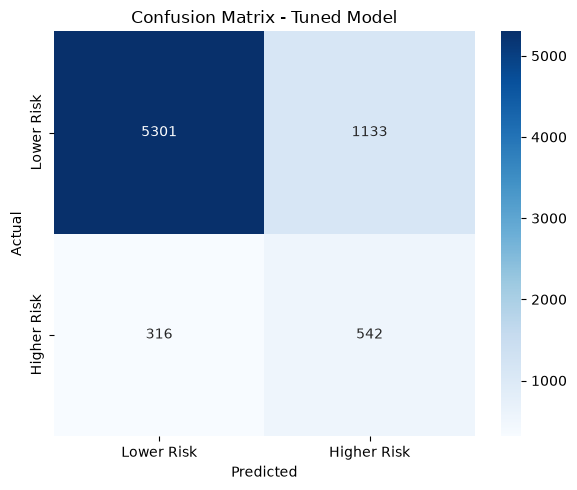

In [8]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Lower Risk", "Higher Risk"],
    yticklabels=["Lower Risk", "Higher Risk"]
)

plt.title("Confusion Matrix - Tuned Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()
